In [2]:
# 运行环境测试

import sys

print("Python:", sys.version)
print("Executable:", sys.executable)

try:
    import torch
    print("PyTorch:", torch.__version__)
    print("MPS available:", torch.backends.mps.is_available())
except ImportError:
    print("PyTorch is not installed in this environment.")


Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:11:29) [Clang 20.1.8 ]
Executable: /opt/anaconda3/bin/python
PyTorch: 2.11.0
MPS available: True


** Step 1: 实现InfoNCE 
每个 Query 对应的正样本放在第0列，其他列是负样本。

In [3]:

import torch
import torch.nn.functional as F

def info_nce_loss(query, positive_key, negative_keys, temperature=0.2):
    """
    query: [B, D]
    positive_key: [B, D]
    negative_keys: [K, D]
    """
    query = F.normalize(query, dim=1)
    positive_key = F.normalize(positive_key, dim=1)
    negative_keys = F.normalize(negative_keys, dim=1)

    positive_logits = torch.sum(
        query * positive_key, dim=1, keepdim=True
    )
    negative_logits = query @ negative_keys.T

    logits = torch.cat(
        [positive_logits, negative_logits], dim=1
    ) / temperature

    labels = torch.zeros(
        query.shape[0], dtype=torch.long, device=query.device
    )

    return F.cross_entropy(logits, labels)


Step 2: 验证样本相似度如何影响Loss

In [4]:

query = torch.tensor([[1.0, 0.0]])
negative_keys = torch.tensor([
    [0.0, 1.0],
    [-1.0, 0.0]
])

positive_examples = {
    "High similarity": torch.tensor([[1.0, 0.0]]),
    "Medium similarity": torch.tensor([[0.7, 0.7]]),
    "Low similarity": torch.tensor([[0.0, 1.0]])
}

for name, positive_key in positive_examples.items():
    loss = info_nce_loss(
        query, positive_key, negative_keys, temperature=0.2
    )
    print(f"{name}: Loss = {loss.item():.4f}")


High similarity: Loss = 0.0068
Medium similarity: Loss = 0.0289
Low similarity: Loss = 0.6965


Step 3: Tempreture 如何调整模型对相似度差异的敏感程度

## Step 3: Understanding the Role of Temperature

Temperature ($\tau$) is a hyperparameter in the InfoNCE loss
that controls how sensitive the softmax distribution is to
differences in similarity scores.

For one positive pair and $K$ negative samples, the loss is

$$
\mathcal{L}_{\mathrm{InfoNCE}}
=
-\log
\frac{\exp(s^+/\tau)}
{\exp(s^+/\tau)+\sum_{i=1}^{K}\exp(s_i^-/\tau)}
$$

where:
- $s^+$ denotes the cosine similarity of the positive pair.
- $s_i^-$ denotes the cosine similarity to the $i$-th negative.
- $\tau > 0$ is the temperature parameter.

### Effect of Temperature

**Low temperature ($\tau$):**
- Produces a sharper softmax distribution.
- Amplifies differences between similarity scores.
- Can produce large losses when negative pairs are more
  similar than the positive pair.

**High temperature ($\tau$):**
- Produces a smoother softmax distribution.
- Reduces sensitivity to similarity differences.
- Changes the relative gradient contributions of samples.

### Hypothesis

Different temperatures will produce different loss
landscapes and gradient behaviour, potentially affecting
the geometry of the learned representations.

We investigate this effect using a simplified
one-positive, one-negative InfoNCE setting.

The interactive Streamlit demo is available in
`demo/app.py`.


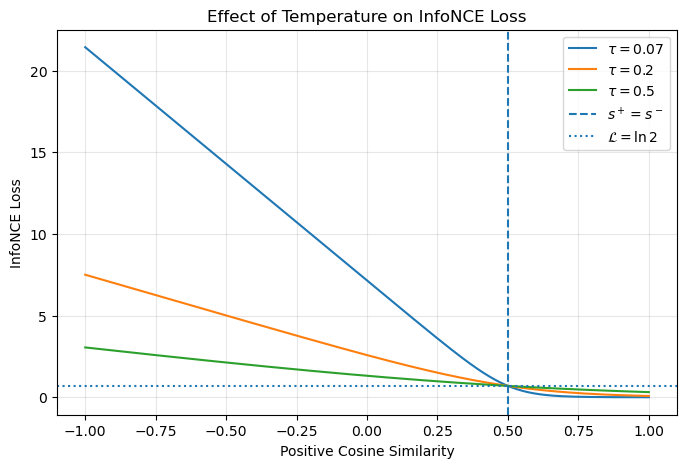

In [7]:

import numpy as np
import matplotlib.pyplot as plt

positive_sim = np.linspace(-1.0, 1.0, 300)
negative_sim = 0.5

temperatures = [0.07, 0.2, 0.5]

plt.figure(figsize=(8, 5))

for tau in temperatures:
    loss = np.logaddexp(
        0.0,
        (negative_sim - positive_sim) / tau
    )

    plt.plot(
        positive_sim,
        loss,
        label=fr"$\tau = {tau}$"
    )

plt.axvline(
    negative_sim,
    linestyle="--",
    label=r"$s^+ = s^-$"
)

plt.axhline(
    np.log(2),
    linestyle=":",
    label=r"$\mathcal{L} = \ln 2$"
)

plt.xlabel("Positive Cosine Similarity")
plt.ylabel("InfoNCE Loss")
plt.title("Effect of Temperature on InfoNCE Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()



### Observations

1. For a fixed negative similarity, the InfoNCE loss
   decreases as positive similarity increases.

2. Smaller temperatures produce steeper loss curves,
   especially when the negative similarity exceeds
   the positive similarity.

3. When positive and negative similarities are equal,
   the loss is $\ln 2$, regardless of temperature.

4. Temperature changes the optimisation signal, but
   a lower temperature does not necessarily guarantee
   better downstream representation quality.

### Conclusion

Temperature controls the sensitivity of contrastive
learning to similarity differences. Its influence on
representation geometry and downstream classification
performance will be investigated in later experiments.


## Step 4: Constructing Positive Pairs with Data Augmentation （构造对比学习正样本对）

In contrastive learning, two independently augmented views of the
same image are treated as a positive pair.

We use CIFAR-10 to visualize how random cropping, horizontal flipping,
color jittering, and grayscale transformations produce different
views of the same underlying image.

In [8]:

import torch
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

# MoCo-style augmentation adapted for CIFAR-10 (32x32 images)
contrastive_transform = transforms.Compose([
    transforms.RandomResizedCrop(
        size=32,
        scale=(0.2, 1.0)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([
        transforms.ColorJitter(
            brightness=0.4,
            contrast=0.4,
            saturation=0.4,
            hue=0.1
        )
    ], p=0.8),
    transforms.RandomGrayscale(p=0.2),
    transforms.ToTensor()
])

# Download CIFAR-10 to the project data directory
dataset = datasets.CIFAR10(
    root="../data",
    train=True,
    download=True,
    transform=None
)

print("Dataset size:", len(dataset))
print("Classes:", dataset.classes)


100%|██████████| 170M/170M [38:17<00:00, 74.2kB/s]   


Dataset size: 50000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


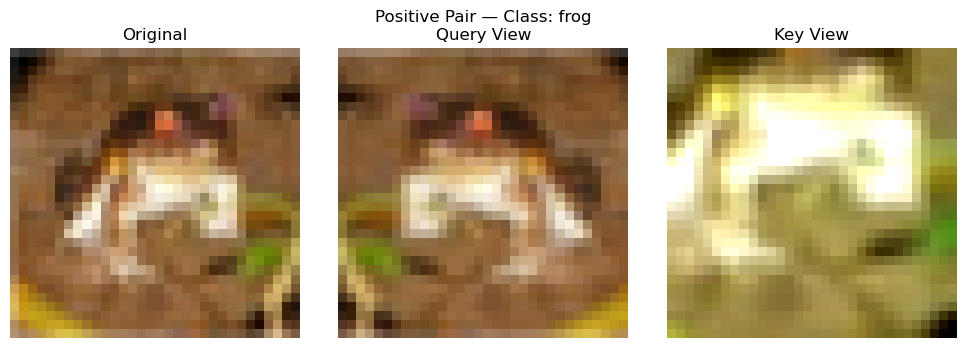

In [9]:
# 生成两张增强图像
# Select one original image
image, label = dataset[0]

# Apply augmentation independently
view1 = contrastive_transform(image)
view2 = contrastive_transform(image)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))

axes[0].imshow(image)
axes[0].set_title("Original")

axes[1].imshow(view1.permute(1, 2, 0))
axes[1].set_title("Query View")

axes[2].imshow(view2.permute(1, 2, 0))
axes[2].set_title("Key View")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"Positive Pair — Class: {dataset.classes[label]}"
)
plt.tight_layout()
plt.show()



### Step 4.1: Exploring CIFAR-10

CIFAR-10 contains 50,000 training images across 10 classes.
Each image has a resolution of 32 × 32 pixels and three RGB channels.

Before constructing contrastive pairs, we visualize representative
samples from each class to understand the dataset's visual diversity.

**Note:** Class labels are used only for visualization and downstream
evaluation, not for MoCo self-supervised pretraining.


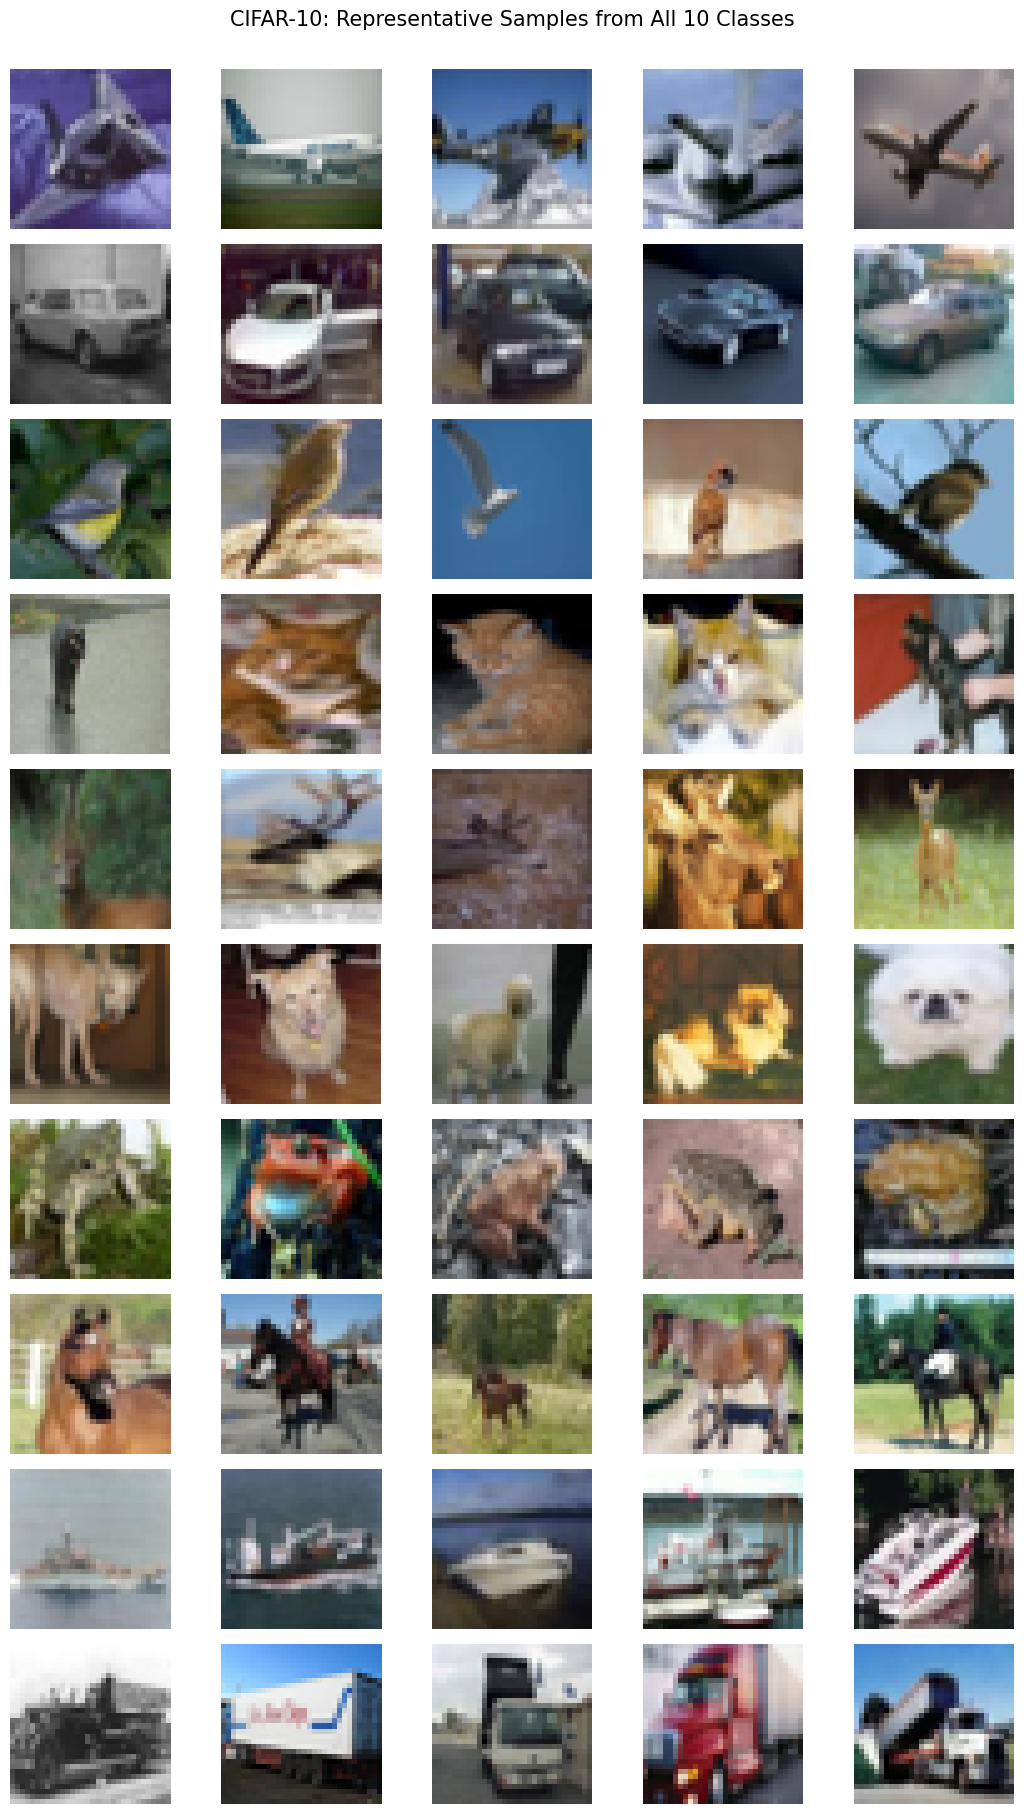

In [10]:

import numpy as np
import matplotlib.pyplot as plt

# Display 5 randomly selected images from each class
rng = np.random.default_rng(42)

targets = np.array(dataset.targets)
num_classes = len(dataset.classes)
samples_per_class = 5

fig, axes = plt.subplots(
    num_classes,
    samples_per_class,
    figsize=(11, 18)
)

for class_idx, class_name in enumerate(dataset.classes):

    indices = np.where(targets == class_idx)[0]

    selected_indices = rng.choice(
        indices,
        size=samples_per_class,
        replace=False
    )

    for col_idx, sample_idx in enumerate(selected_indices):
        image, _ = dataset[int(sample_idx)]

        ax = axes[class_idx, col_idx]
        ax.imshow(image)
        ax.axis("off")

        if col_idx == 0:
            ax.set_ylabel(
                class_name,
                fontsize=11,
                rotation=0,
                labelpad=55,
                va="center"
            )

plt.suptitle(
    "CIFAR-10: Representative Samples from All 10 Classes",
    fontsize=15,
    y=1.005
)

plt.tight_layout()
plt.show()


In [11]:
# 封装成真正的数据集

from torch.utils.data import Dataset, DataLoader

class TwoViewDataset(Dataset):
    def __init__(self, base_dataset, transform):
        self.base_dataset = base_dataset
        self.transform = transform

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, index):
        image, label = self.base_dataset[index]

        query_view = self.transform(image)
        key_view = self.transform(image)

        return query_view, key_view, label


two_view_dataset = TwoViewDataset(
    dataset,
    contrastive_transform
)

loader = DataLoader(
    two_view_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0
)

q, k, labels = next(iter(loader))

print("Query shape:", q.shape)
print("Key shape:", k.shape)
print("Labels shape:", labels.shape)


Query shape: torch.Size([64, 3, 32, 32])
Key shape: torch.Size([64, 3, 32, 32])
Labels shape: torch.Size([64])
